<a href="https://colab.research.google.com/github/Mirza-PU/BF-IT2FIDS/blob/main/Correction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using computing device: cuda
GPU Device Name: Tesla T4
Using Colab cache for faster access to the 'edge-iiotset-dataset' dataset.
✔ Dataset downloaded at: /kaggle/input/edge-iiotset-dataset
DATA SHAPE: (157800, 63)
TARGET USED: Attack_type
NUM CLASSES: 15

STARTING 10-SEED STATISTICAL EVALUATION: BF-IT2FIDS
 -> Seed 42    | Test Acc: 99.58% | Epochs: 37
 -> Seed 100   | Test Acc: 99.52% | Epochs: 59
 -> Seed 2026  | Test Acc: 99.63% | Epochs: 71
 -> Seed 7     | Test Acc: 99.58% | Epochs: 28
 -> Seed 123   | Test Acc: 99.54% | Epochs: 22
 -> Seed 999   | Test Acc: 99.51% | Epochs: 29
 -> Seed 2024  | Test Acc: 99.51% | Epochs: 37
 -> Seed 555   | Test Acc: 99.51% | Epochs: 33
 -> Seed 888   | Test Acc: 99.49% | Epochs: 22
 -> Seed 77    | Test Acc: 99.51% | Epochs: 43

✔ BEST SEED IDENTIFIED: 2026 (Test Accuracy: 99.63%)

Generating publication-ready figures...


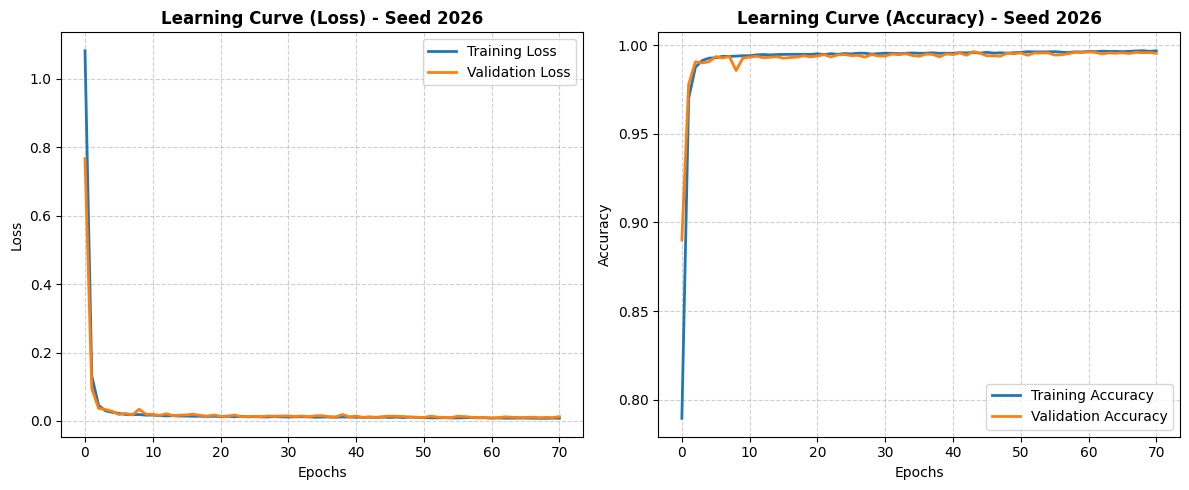

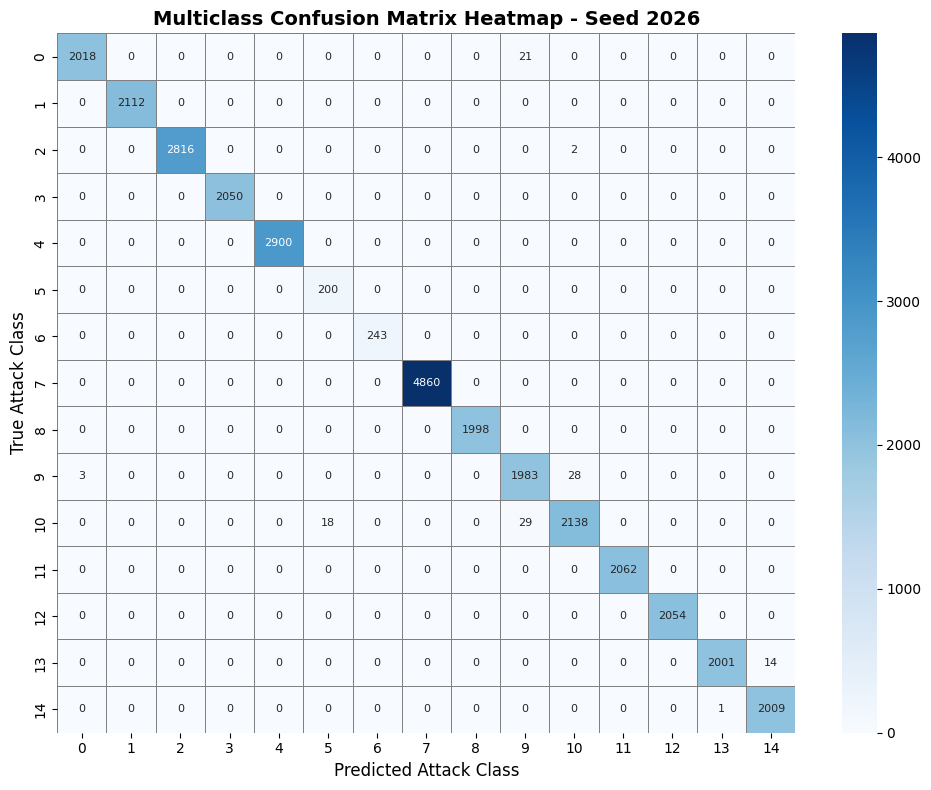

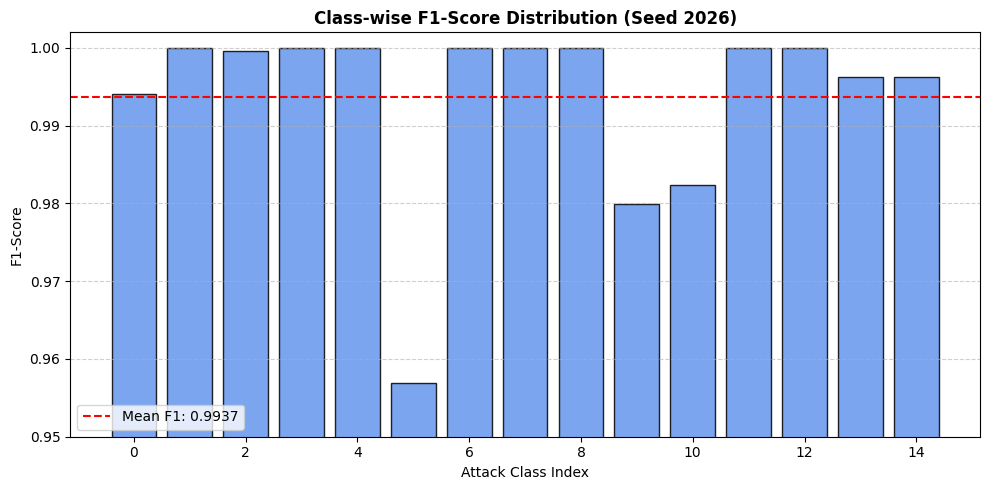


10-SEED FINAL PERFORMANCE SUMMARY
Seed 42   | Train Acc: 0.9953 | Test Acc: 0.9958
Seed 100  | Train Acc: 0.9953 | Test Acc: 0.9952
Seed 2026 | Train Acc: 0.9967 | Test Acc: 0.9963
Seed 7    | Train Acc: 0.9961 | Test Acc: 0.9958
Seed 123  | Train Acc: 0.9949 | Test Acc: 0.9954
Seed 999  | Train Acc: 0.9954 | Test Acc: 0.9951
Seed 2024 | Train Acc: 0.9953 | Test Acc: 0.9951
Seed 555  | Train Acc: 0.9962 | Test Acc: 0.9951
Seed 888  | Train Acc: 0.9951 | Test Acc: 0.9949
Seed 77   | Train Acc: 0.9960 | Test Acc: 0.9951
----------------------------------------
Mean Train Accuracy : 0.9956
Mean Test Accuracy  : 0.9954 (±0.0004)

RUNNING 4-WAY ABLATION STUDY ACROSS 10 SEEDS (GPU)

--- Evaluating Model: 1. Simple MLP (Raw) ---
[Summary] 1. Simple MLP (Raw) -> Mean Acc: 53.10% (±2.83%) | Mean F1: 0.4943

--- Evaluating Model: 2. BF-IT2FIDS (Fuzzy MLP - Ours) ---
[Summary] 2. BF-IT2FIDS (Fuzzy MLP - Ours) -> Mean Acc: 99.54% (±0.04%) | Mean F1: 0.9913

--- Evaluating Model: 3. Progressive Pr

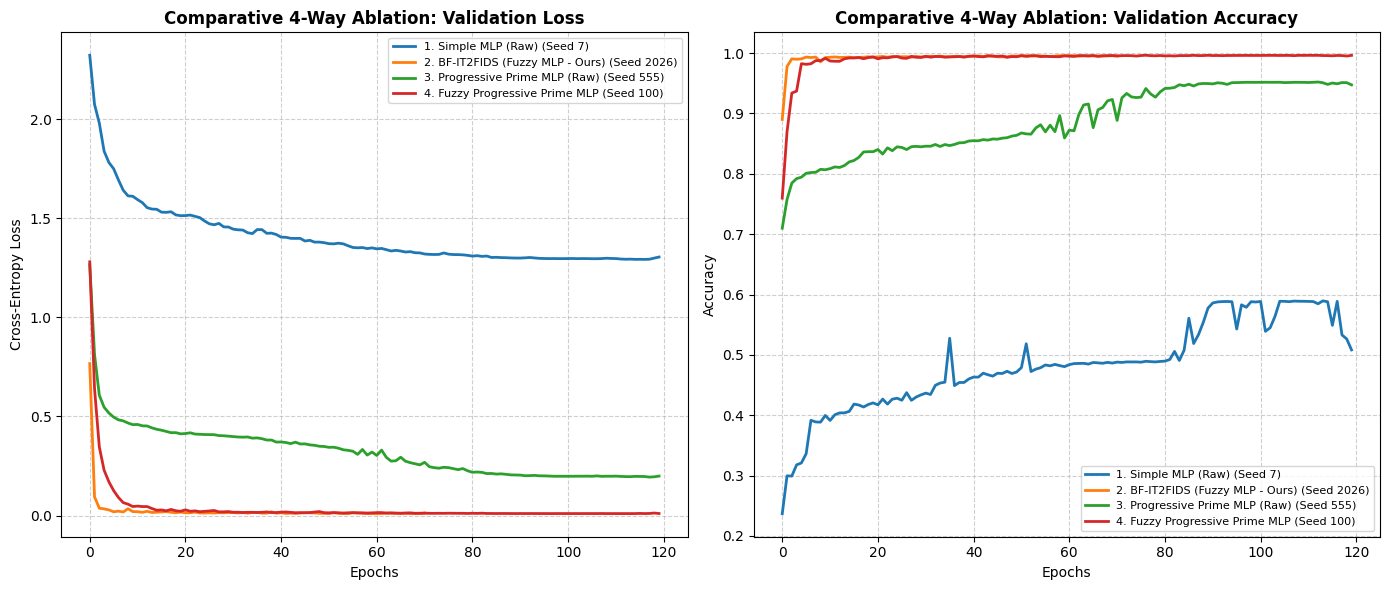

✔ Ablation learning curves saved successfully!


In [ ]:

# =====================================================
# COMPLETE UNIFIED & GPU-OPTIMIZED PIPELINE FOR RESUBMISSION
# BF-IT2FIDS & 4-WAY ABLATION STUDY
# =====================================================

import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score

# =====================================================
# 1. DEVICE CONFIGURATION (GPU ENFORCEMENT)
# =====================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using computing device:", device)
if device.type == "cuda":
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
    torch.backends.cudnn.benchmark = True

# =====================================================
# 2. DOWNLOAD & LOAD DATASET
# =====================================================
import kagglehub
dataset_path = kagglehub.dataset_download("sibasispradhan/edge-iiotset-dataset")
print("✔ Dataset downloaded at:", dataset_path)

file_name = "ML-EdgeIIoT-dataset.csv"
data_path = None
for root, _, files in os.walk(dataset_path):
    if file_name in files:
        data_path = os.path.join(root, file_name)
        break

if data_path is None:
    raise FileNotFoundError("Dataset CSV not found in downloaded path!")

data = pd.read_csv(data_path, low_memory=False)
print("DATA SHAPE:", data.shape)

# =====================================================
# 3. TARGET RESOLUTION & DATA CLEANING
# =====================================================
if "Attack_type" in data.columns:
    target = "Attack_type"
elif "Attack_cat" in data.columns:
    target = "Attack_cat"
else:
    target = "Attack_label"

print("TARGET USED:", target)

y_raw = data[target]
X_raw = data.drop(columns=[target])

X_raw = X_raw.fillna(0)
for col in X_raw.columns:
    if X_raw[col].dtype == "object":
        X_raw[col] = LabelEncoder().fit_transform(X_raw[col].astype(str))

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
X = X_raw.values

print("NUM CLASSES:", len(np.unique(y)))

# =====================================================
# 4. STRICT LEAKAGE-FREE & MATHEMATICALLY CORRECT FUZZY TRANSFORM
# =====================================================
def fuzzy_transform(arr, centers, scales):
    features = []
    for i in range(arr.shape[1]):
        x = (arr[:, i] - centers[i]) / scales[i]

        # Mathematical Correction (Reviewer 1, Point 1):
        # Enforce Footprint of Uncertainty (FOU) condition: lower <= upper
        # - Narrower spread (sigma_1^2 = 0.3) -> Lower Membership Bound (\underline{mu})
        # - Wider spread (sigma_2^2 = 0.7)    -> Upper Membership Bound (\bar{mu})
        lower = np.exp(-(x ** 2) / 0.3)
        upper = np.exp(-(x ** 2) / 0.7)

        # Bipolar Fuzzy Truth and Falsity Polarities
        pos = 1 / (1 + np.exp(-x))
        neg = 1 - pos

        features += [lower, upper, pos, neg]
    return np.stack(features, axis=1)

# =====================================================
# 5. MODEL ARCHITECTURES (FAIRLY BACKBONE-MATCHED [512, 256, 128])
# =====================================================
class BF_IT2FIDS(nn.Module):
    """Core Proposed Fuzzy MLP (BF-IT2FIDS) - [512, 256, 128]"""
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)


class SimpleMLP(nn.Module):
    """Baseline Standard MLP (Raw Features) - Fairly Matched [512, 256, 128] Architecture"""
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)


class ProgressivePrimeMLP(nn.Module):
    """Progressive Prime Bottleneck Topology with LayerNorm"""
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 67), nn.LayerNorm(67), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(67, 131), nn.LayerNorm(131), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(131, 257), nn.LayerNorm(257), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(257, 131), nn.LayerNorm(131), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(131, 67), nn.LayerNorm(67), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(67, num_classes)
        )
    def forward(self, x):
        return self.net(x)


# =====================================================
# 6. 10-SEED EVALUATION PIPELINE FOR MAIN BF-IT2FIDS MODEL
# =====================================================
SEEDS = [42, 100, 2026, 7, 123, 999, 2024, 555, 888, 77]
seed_results = []

print("\n==================================================")
print("STARTING 10-SEED STATISTICAL EVALUATION: BF-IT2FIDS")
print("==================================================")

for seed in SEEDS:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Stratified Split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed, stratify=y
    )
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=0.125, random_state=seed, stratify=y_train
    )

    # Scaling (Training-Only Fit to Prevent Leakage)
    scaler = RobustScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_val_s = scaler.transform(X_val)
    X_test_s = scaler.transform(X_test)

    # Fuzzy Transformation (Training-Only Statistics)
    centers = np.median(X_tr_s, axis=0)
    scales = np.std(X_tr_s, axis=0) + 1e-6

    X_tr_f = fuzzy_transform(X_tr_s, centers, scales)
    X_val_f = fuzzy_transform(X_val_s, centers, scales)
    X_test_f = fuzzy_transform(X_test_s, centers, scales)

    # Tensor Allocation to GPU
    X_train_t = torch.tensor(X_tr_f, dtype=torch.float32).to(device)
    X_val_t = torch.tensor(X_val_f, dtype=torch.float32).to(device)
    X_test_t = torch.tensor(X_test_f, dtype=torch.float32).to(device)

    y_train_t = torch.tensor(y_tr, dtype=torch.long).to(device)
    y_val_t = torch.tensor(y_val, dtype=torch.long).to(device)
    y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

    # Balanced Class Weights
    weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_tr), y=y_tr)
    weights_t = torch.tensor(weights, dtype=torch.float32).to(device)

    model = BF_IT2FIDS(input_dim=X_tr_f.shape[1], num_classes=len(np.unique(y))).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights_t)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

    best_val_loss = float('inf')
    best_model_state = None
    train_loss_hist, val_loss_hist, train_acc_hist, val_acc_hist = [], [], [], []
    patience, patience_counter = 10, 0

    for epoch in range(120):
        model.train()
        total_loss, correct_train, total_train = 0, 0, 0
        for i in range(0, len(X_train_t), 4096):
            xb = X_train_t[i:i+4096]
            yb = y_train_t[i:i+4096]

            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item()
            preds_train = torch.argmax(out, dim=1)
            correct_train += (preds_train == yb).sum().item()
            total_train += yb.size(0)

        scheduler.step()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t)
            val_loss = criterion(val_logits, y_val_t).item()
            val_preds = torch.argmax(val_logits, dim=1)
            val_acc = (val_preds == y_val_t).sum().item() / y_val_t.size(0)

        train_loss_hist.append(total_loss / (len(X_train_t) / 4096))
        val_loss_hist.append(val_loss)
        train_acc_hist.append(correct_train / total_train)
        val_acc_hist.append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = {k: v.cpu() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    if best_model_state is not None:
        model.load_state_dict({k: v.to(device) for k, v in best_model_state.items()})

    model.eval()
    with torch.no_grad():
        train_final_logits = model(X_train_t)
        final_train_preds = torch.argmax(train_final_logits, dim=1).cpu().numpy()
        final_train_acc = accuracy_score(y_tr, final_train_preds)

        logits = model(X_test_t)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1).cpu().numpy()
        risk = torch.max(probs, dim=1).values.cpu().numpy()

    test_acc = accuracy_score(y_test, preds)
    seed_results.append({
        "seed": seed, "accuracy": test_acc, "train_accuracy": final_train_acc,
        "preds": preds, "y_test": y_test, "risk": risk,
        "train_loss": train_loss_hist, "val_loss": val_loss_hist,
        "train_acc": train_acc_hist, "val_acc": val_acc_hist
    })
    print(f" -> Seed {seed:<5} | Test Acc: {test_acc*100:.2f}% | Epochs: {len(val_loss_hist)}")

# Identify Best Seed
best_result = max(seed_results, key=lambda x: x["accuracy"])
best_seed = best_result["seed"]
print(f"\n✔ BEST SEED IDENTIFIED: {best_seed} (Test Accuracy: {best_result['accuracy']*100:.2f}%)")

# =====================================================
# 7. GENERATE HIGH-RESOLUTION (300 DPI) FIGURES
# =====================================================
print("\nGenerating publication-ready figures...")

# 1. Learning Curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(best_result['train_loss'], label="Training Loss", linewidth=2)
plt.plot(best_result['val_loss'], label="Validation Loss", linewidth=2)
plt.title(f"Learning Curve (Loss) - Seed {best_seed}", fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(best_result['train_acc'], label="Training Accuracy", linewidth=2)
plt.plot(best_result['val_acc'], label="Validation Accuracy", linewidth=2)
plt.title(f"Learning Curve (Accuracy) - Seed {best_seed}", fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("Learning curve.png", dpi=300)
plt.show()

# 2. Confusion Matrix Heatmap
cm_mc = confusion_matrix(best_result['y_test'], best_result['preds'])
plt.figure(figsize=(10, 8))
sns.heatmap(cm_mc, annot=True, fmt="d", cmap="Blues", cbar=True, linewidths=0.5, linecolor='gray', annot_kws={"size": 8})
plt.title(f"Multiclass Confusion Matrix Heatmap - Seed {best_seed}", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Attack Class", fontsize=12)
plt.ylabel("True Attack Class", fontsize=12)
plt.tight_layout()
plt.savefig("Confussion Matrix.png", dpi=300)
plt.show()

# 3. Class-wise F1 Distribution
class_f1s = f1_score(best_result['y_test'], best_result['preds'], average=None)
classes = np.unique(best_result['y_test'])
plt.figure(figsize=(10, 5))
plt.bar(classes, class_f1s, color="cornflowerblue", edgecolor="black", alpha=0.85)
plt.axhline(y=np.mean(class_f1s), color="red", linestyle="--", label=f"Mean F1: {np.mean(class_f1s):.4f}")
plt.title(f"Class-wise F1-Score Distribution (Seed {best_seed})", fontsize=12, fontweight="bold")
plt.xlabel("Attack Class Index")
plt.ylabel("F1-Score")
plt.ylim(0.95, 1.002)
plt.legend(loc="lower left")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("Class wise F1 score distribution.png", dpi=300)
plt.show()

# =====================================================
# 8. 10-SEED STATISTICAL SUMMARY REPORT
# =====================================================
print("\n========================================")
print("10-SEED FINAL PERFORMANCE SUMMARY")
print("========================================")
accuracies = [res["accuracy"] for res in seed_results]
train_accuracies = [res["train_accuracy"] for res in seed_results]
for res in seed_results:
    print(f"Seed {res['seed']:<4} | Train Acc: {res['train_accuracy']:.4f} | Test Acc: {res['accuracy']:.4f}")
print("----------------------------------------")
print(f"Mean Train Accuracy : {np.mean(train_accuracies):.4f}")
print(f"Mean Test Accuracy  : {np.mean(accuracies):.4f} (±{np.std(accuracies):.4f})")
print("========================================")

# =====================================================
# 9. 4-WAY ABLATION STUDY ACROSS 10 SEEDS (GPU ACCELERATED)
# =====================================================
print("\n========================================================")
print("RUNNING 4-WAY ABLATION STUDY ACROSS 10 SEEDS (GPU)")
print("========================================================")

def evaluate_ablation_model(model_class, use_fuzzy, model_name):
    print(f"\n--- Evaluating Model: {model_name} ---")
    seed_accs, seed_f1s, seed_times = [], [], []
    best_acc, best_metrics = -1, None

    for seed in SEEDS:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
        X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=seed, stratify=y_train)

        scaler = RobustScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_val_s = scaler.transform(X_val)
        X_test_s = scaler.transform(X_test)

        if use_fuzzy:
            centers = np.median(X_tr_s, axis=0)
            scales = np.std(X_tr_s, axis=0) + 1e-6
            X_tr_f = fuzzy_transform(X_tr_s, centers, scales)
            X_val_f = fuzzy_transform(X_val_s, centers, scales)
            X_test_f = fuzzy_transform(X_test_s, centers, scales)

            X_tr_t = torch.tensor(X_tr_f, dtype=torch.float32).to(device)
            X_val_t = torch.tensor(X_val_f, dtype=torch.float32).to(device)
            X_test_t = torch.tensor(X_test_f, dtype=torch.float32).to(device)
            input_dim = X_tr_f.shape[1]
        else:
            X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32).to(device)
            X_val_t = torch.tensor(X_val_s, dtype=torch.float32).to(device)
            X_test_t = torch.tensor(X_test_s, dtype=torch.float32).to(device)
            input_dim = X_tr_s.shape[1]

        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(device)
        y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

        weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_tr), y=y_tr)
        weights_t = torch.tensor(weights, dtype=torch.float32).to(device)

        model = model_class(input_dim=input_dim, num_classes=len(np.unique(y))).to(device)
        criterion = nn.CrossEntropyLoss(weight=weights_t)
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

        best_val_loss = float('inf')
        best_state = None
        val_loss_hist, val_acc_hist = [], []
        start_time = time.time()
        patience_counter = 0

        for epoch in range(120):
            model.train()
            for i in range(0, len(X_tr_t), 4096):
                xb = X_tr_t[i:i+4096]
                yb = y_tr_t[i:i+4096]

                optimizer.zero_grad()
                out = model(xb)
                loss = criterion(out, yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            scheduler.step()

            model.eval()
            with torch.no_grad():
                val_logits = model(X_val_t)
                val_loss = criterion(val_logits, y_val_t).item()
                val_preds = torch.argmax(val_logits, dim=1)
                val_acc = (val_preds == y_val_t).sum().item() / y_val_t.size(0)

            val_loss_hist.append(val_loss)
            val_acc_hist.append(val_acc)

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = {k: v.cpu() for k, v in model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= 10:
                    break

        training_time = time.time() - start_time
        model.load_state_dict({k: v.to(device) for k, v in best_state.items()})

        model.eval()
        with torch.no_grad():
            test_logits = model(X_test_t)
            test_preds = torch.argmax(test_logits, dim=1).cpu().numpy()
            test_acc = accuracy_score(y_test, test_preds)

        report = classification_report(y_test, test_preds, output_dict=True, zero_division=0)
        macro_f1 = report['macro avg']['f1-score']

        seed_accs.append(test_acc)
        seed_f1s.append(macro_f1)
        seed_times.append(training_time)

        if test_acc > best_acc:
            best_acc = test_acc
            best_metrics = {"seed": seed, "val_loss": val_loss_hist, "val_acc": val_acc_hist}

    mean_acc, std_acc = np.mean(seed_accs), np.std(seed_accs)
    mean_f1, mean_time = np.mean(seed_f1s), np.mean(seed_times)
    print(f"[Summary] {model_name} -> Mean Acc: {mean_acc*100:.2f}% (±{std_acc*100:.2f}%) | Mean F1: {mean_f1:.4f}")

    return {
        "model_name": model_name, "mean_acc": mean_acc, "std_acc": std_acc,
        "mean_f1": mean_f1, "mean_time": mean_time, "best_metrics": best_metrics
    }

# Execute 4-Way Ablation Study
ablation_results = []
ablation_results.append(evaluate_ablation_model(SimpleMLP, use_fuzzy=False, model_name="1. Simple MLP (Raw)"))
ablation_results.append(evaluate_ablation_model(BF_IT2FIDS, use_fuzzy=True, model_name="2. BF-IT2FIDS (Fuzzy MLP - Ours)"))
ablation_results.append(evaluate_ablation_model(ProgressivePrimeMLP, use_fuzzy=False, model_name="3. Progressive Prime MLP (Raw)"))
ablation_results.append(evaluate_ablation_model(ProgressivePrimeMLP, use_fuzzy=True, model_name="4. Fuzzy Progressive Prime MLP"))

# Final Ablation Summary Table Printout
print("\n==========================================================================")
print("10-SEED 4-WAY ABLATION STUDY FINAL PERFORMANCE TABLE")
print("==========================================================================")
print(f"{'Model Architecture':<36} | {'Mean Acc (%)':<14} | {'Mean Macro F1':<15} | {'Mean Time (s)':<12}")
print("-" * 83)
for res in ablation_results:
    print(f"{res['model_name']:<36} | {res['mean_acc']*100:.2f}% (±{res['std_acc']*100:.2f}%)   | {res['mean_f1']:.4f}          | {res['mean_time']:.1f}s")
print("==========================================================================")

# Generate Ablation Learning Curves Figure
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
for res in ablation_results:
    bm = res['best_metrics']
    plt.plot(bm['val_loss'], label=f"{res['model_name']} (Seed {bm['seed']})", linewidth=2)
plt.title("Comparative 4-Way Ablation: Validation Loss", fontsize=12, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
for res in ablation_results:
    bm = res['best_metrics']
    plt.plot(bm['val_acc'], label=f"{res['model_name']} (Seed {bm['seed']})", linewidth=2)
plt.title("Comparative 4-Way Ablation: Validation Accuracy", fontsize=12, fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("four_way_200ep_10seed_ablation_validation accuracy-validation loss.png", dpi=300)
plt.show()
print("✔ Ablation learning curves saved successfully!")